# Desafio: Detecção de Anomalias em Turbinas Eólicas
**Mineração de Dados – UFC** · Notebook da equipe


Meta: entregar **no máximo 300 alertas** (ids) e defender qual método vocês colocariam em produção.

In [ ]:
import os
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
pd.options.display.precision = 2

NUM = ['vento_ms','potencia_kw','rotor_rpm','temp_caixa_engrenagem_c','vibracao_mm_s','temp_ambiente_c']

### Carregamento

Se tiverem só a versão `.xlsx` (aberta no Excel/Google Sheets), cuidado: a planilha transforma números como `2.09` em data (2 de setembro).
A célula abaixo desfaz isso usando o formato salvo em cada célula (`d.m`, `dd.mm`, `yyyy.m`, `yyyy.mm`). Com o CSV original ela não faz nada.

In [ ]:
arquivo = 'telemetria_parque_eolico.csv'

if not os.path.exists(arquivo):
    import openpyxl, datetime as dt
    ws = openpyxl.load_workbook('telemetria_parque_eolico.xlsx').active
    linhas = list(ws.iter_rows())
    cab = [x.value for x in linhas[0]]

    def valor(cel):
        v, f = cel.value, cel.number_format
        if not isinstance(v, dt.datetime) or cab[cel.column - 1] == 'timestamp':
            return v
        if f == 'd.m':     return float(f'{v.day}.{v.month}')
        if f == 'dd.mm':   return float(f'{v.day}.{v.month:02d}')
        if f == 'yyyy.m':  return float(f'{v.year}.{v.month}')
        if f == 'yyyy.mm': return float(f'{v.year}.{v.month:02d}')

    tab = pd.DataFrame([[valor(x) for x in l] for l in linhas[1:]], columns=cab)
    tab[NUM] = tab[NUM].apply(pd.to_numeric)
    tab['id'] = tab.id.astype(int)
    tab.to_csv(arquivo, index=False)

d = pd.read_csv(arquivo, parse_dates=['timestamp'])
d = d.sort_values(['turbina', 'timestamp']).reset_index(drop=True)
d.head()

,id,timestamp,turbina,vento_ms,potencia_kw,rotor_rpm,temp_caixa_engrenagem_c,vibracao_mm_s,temp_ambiente_c
0,1,2026-08-03 00:00:00,T01,6.47,144.89,12.40,39.57,3.64,22.83
1,2,2026-08-03 00:10:00,T01,5.81,75.87,11.81,37.67,3.29,22.75
2,3,2026-08-03 00:20:00,T01,6.19,39.77,12.49,37.94,3.26,22.01
3,4,2026-08-03 00:30:00,T01,6.64,189.66,12.09,37.49,3.28,22.39
4,5,2026-08-03 00:40:00,T01,5.44,20.01,11.11,36.03,2.90,23.34


## Etapa 1 · Entender os dados
Dica: a relação **vento × potência** é a curva de potência da turbina. Como fica um ponto que foge dela?

In [ ]:
d[NUM].describe().round(2)

,vento_ms,potencia_kw,rotor_rpm,temp_caixa_engrenagem_c,vibracao_mm_s,temp_ambiente_c
count,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00
mean,8.63,710.52,14.52,49.76,3.84,26.00
std,2.45,656.08,2.53,10.48,0.68,2.87
min,2.02,0.00,0.03,32.36,0.90,20.65
25%,6.67,136.69,12.66,40.36,3.46,23.23
50%,8.67,493.78,14.67,47.42,3.84,25.99
75%,10.54,1176.94,16.57,58.11,4.20,28.77
max,15.00,2050.00,19.20,95.15,13.48,31.42


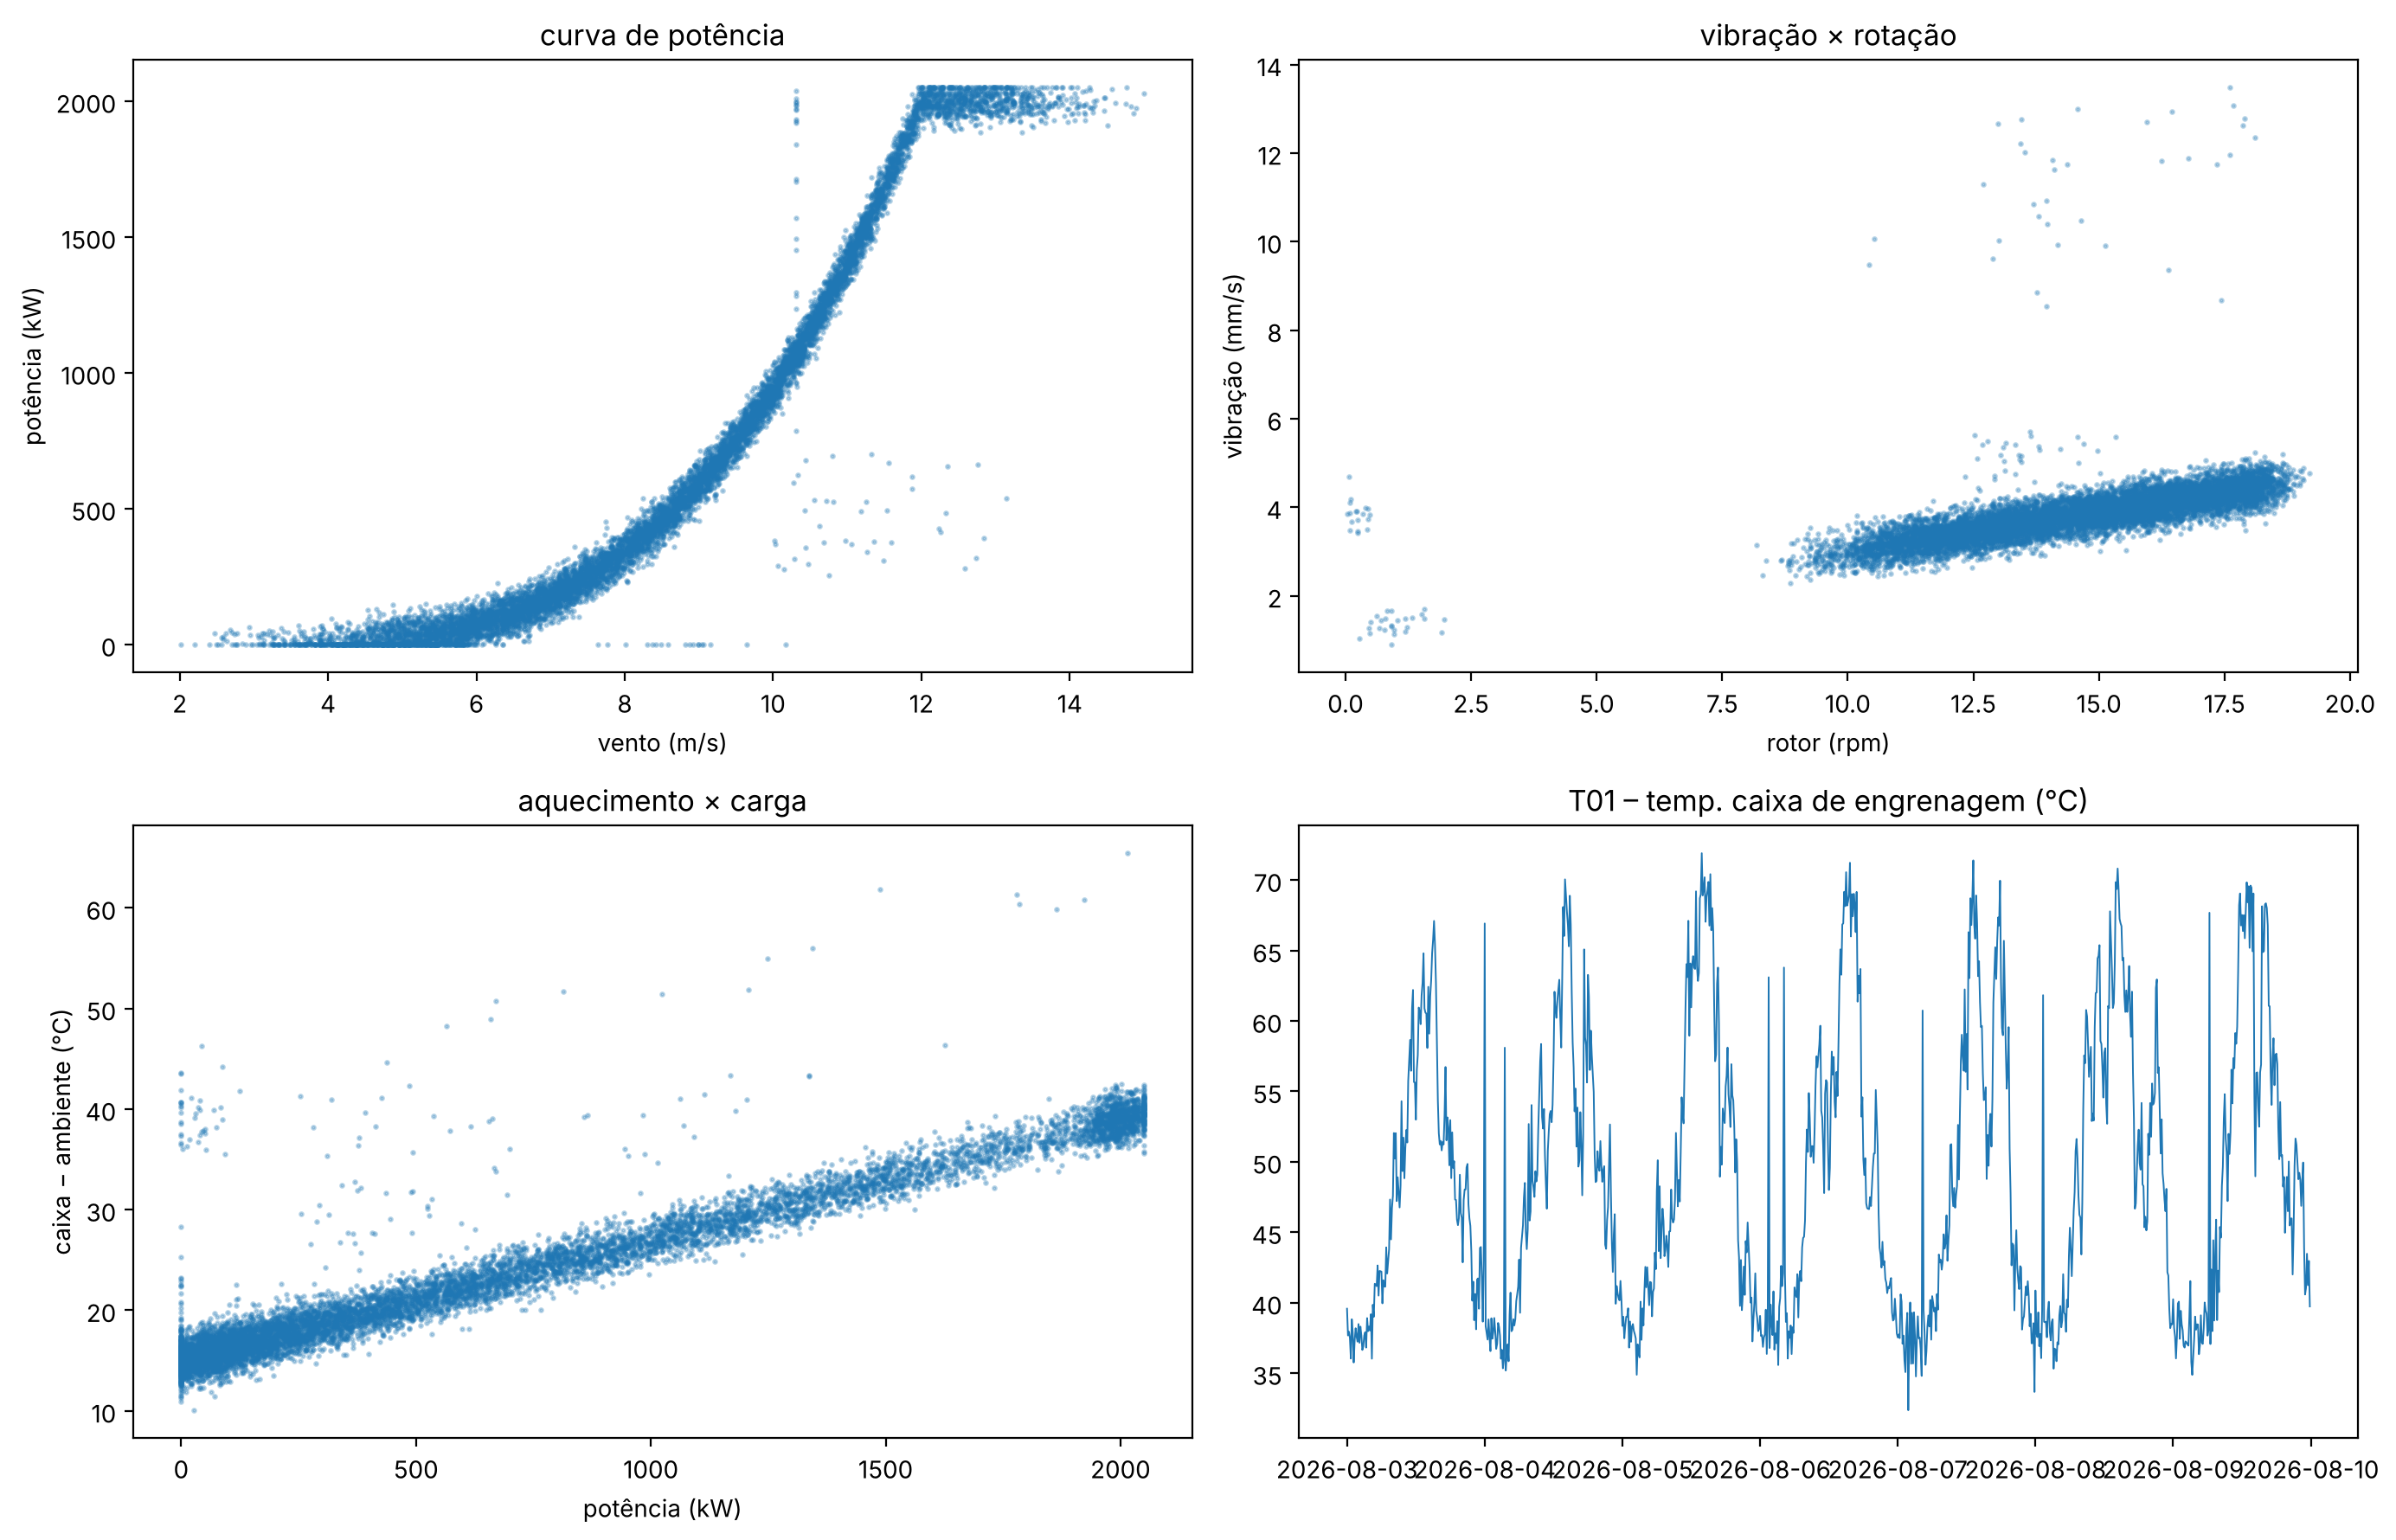

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0, 0].scatter(d.vento_ms, d.potencia_kw, s=2, alpha=.3)
ax[0, 0].set_xlabel('vento (m/s)'); ax[0, 0].set_ylabel('potência (kW)'); ax[0, 0].set_title('curva de potência')

ax[0, 1].scatter(d.rotor_rpm, d.vibracao_mm_s, s=2, alpha=.3)
ax[0, 1].set_xlabel('rotor (rpm)'); ax[0, 1].set_ylabel('vibração (mm/s)'); ax[0, 1].set_title('vibração × rotação')

ax[1, 0].scatter(d.potencia_kw, d.temp_caixa_engrenagem_c - d.temp_ambiente_c, s=2, alpha=.3)
ax[1, 0].set_xlabel('potência (kW)'); ax[1, 0].set_ylabel('caixa − ambiente (°C)'); ax[1, 0].set_title('aquecimento × carga')

t = d[d.turbina == 'T01']
ax[1, 1].plot(t.timestamp, t.temp_caixa_engrenagem_c, lw=.7)
ax[1, 1].set_title('T01 – temp. caixa de engrenagem (°C)')
plt.tight_layout()

**O que dá pra ver a olho:**
- Curva de potência: uma nuvem de pontos com vento entre 10 e 13 m/s gerando só 250–700 kW (deveria ser 1.100–2.000 kW).
- Uma **linha vertical** em vento ≈ 10,3 m/s com potência variando de 1.000 a 2.000 kW: o vento "não mudou" enquanto a potência mudava → suspeita de anemômetro travado.
- Pontos com potência 0 e vento de 8–10 m/s: turbina parada com vento bom.
- Vibração: picos de 8 a 13 mm/s, quando o normal é 3–5 mm/s.
- Temperatura: alguns pontos bem acima da reta "aquecimento × carga", inclusive com potência quase zero.

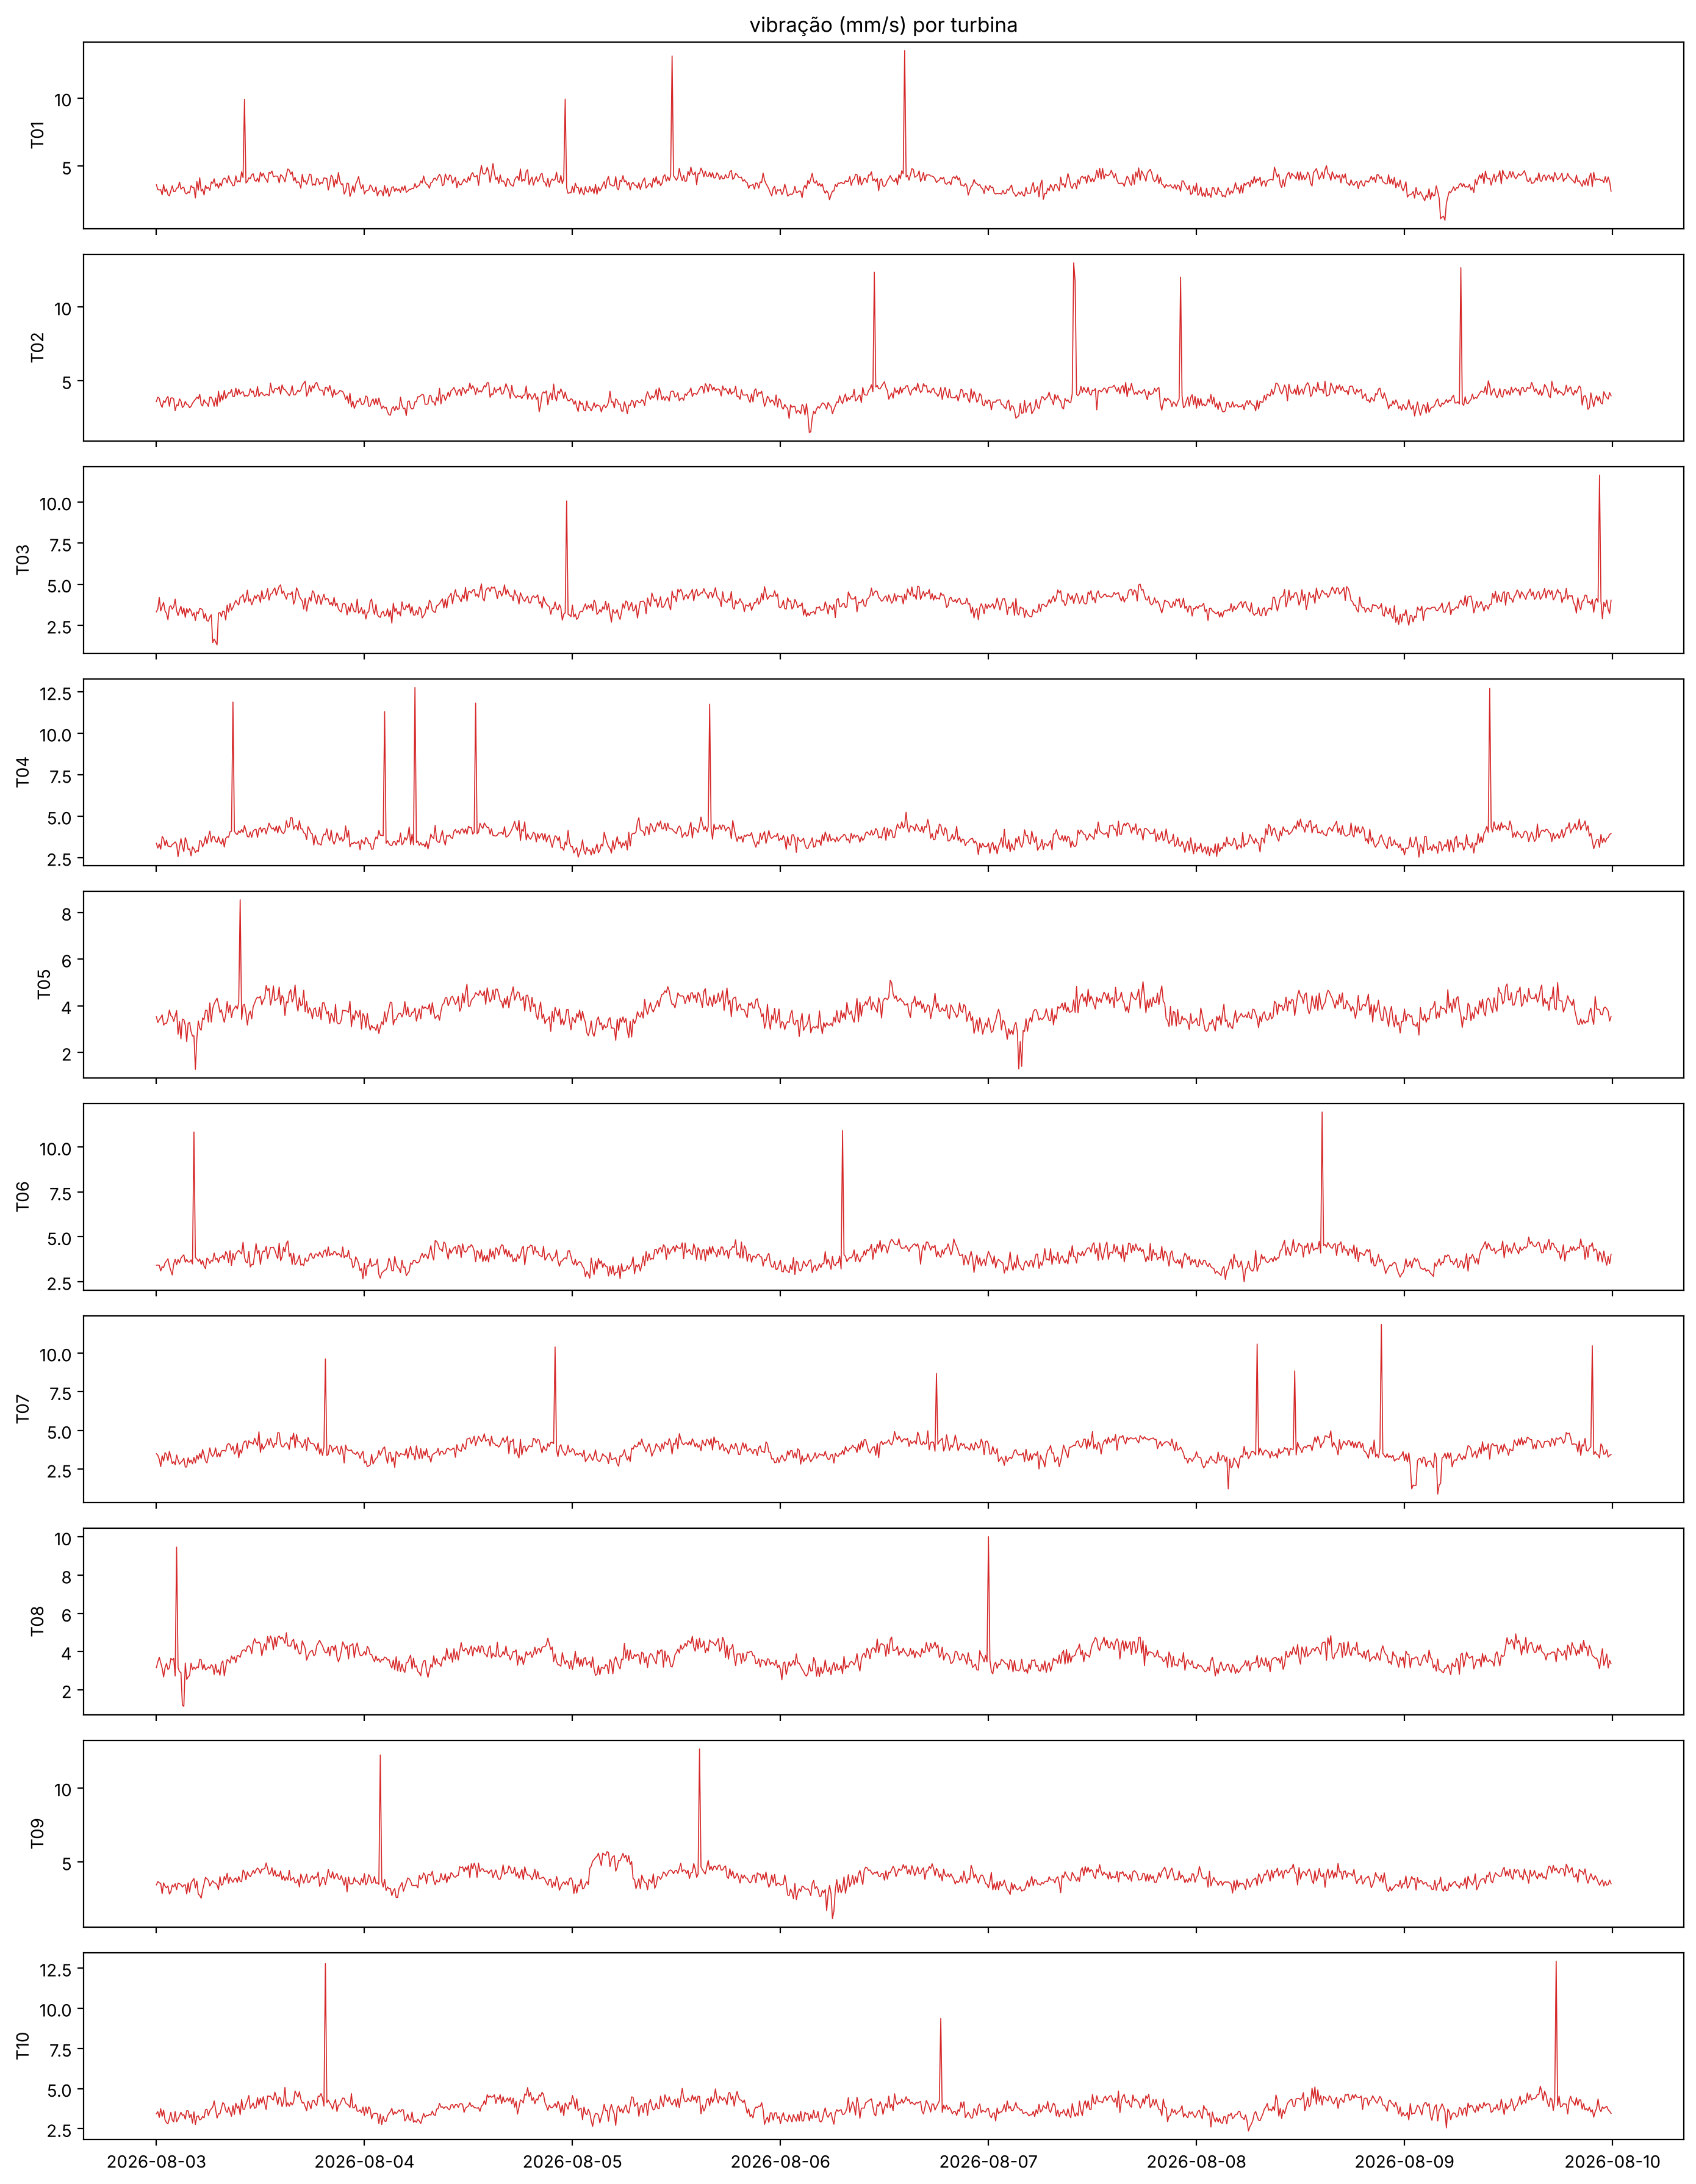

In [ ]:
# série de vibração por turbina (o que é suave e o que é pico)
fig, ax = plt.subplots(10, 1, figsize=(14, 18), sharex=True)
for i, (nome, g) in enumerate(d.groupby('turbina')):
    ax[i].plot(g.timestamp, g.vibracao_mm_s, lw=.6, c='tab:red')
    ax[i].set_ylabel(nome)
ax[0].set_title('vibração (mm/s) por turbina')
plt.tight_layout()

Além dos picos isolados, a **T09** tem um trecho de algumas horas com vibração alta e contínua na madrugada de 05/08, e a **T05** tem um degrau na madrugada de 09/08 (é o período em que ela está parada).

## Etapa 2 · Baseline estatístico
Z-Score já está pronto. Implementem o IQR e comparem: o que cada um encontra? O que **não** conseguem encontrar?

In [ ]:
z = ((d[NUM] - d[NUM].mean()) / d[NUM].std()).abs()
d['alerta_z'] = (z > 3).any(axis=1)
print(d.alerta_z.sum(), 'alertas pelo Z-Score')

q1, q3 = d[NUM].quantile(0.25), d[NUM].quantile(0.75)
iqr = q3 - q1
fora = (d[NUM] < q1 - 1.5 * iqr) | (d[NUM] > q3 + 1.5 * iqr)
d['alerta_iqr'] = fora.any(axis=1)
print(d.alerta_iqr.sum(), 'alertas pelo IQR')
print((d.alerta_z & d.alerta_iqr).sum(), 'em comum')

print('\nalertas por variável:')
print(pd.DataFrame({'z': (z > 3).sum(), 'iqr': fora.sum()}))

87 alertas pelo Z-Score
100 alertas pelo IQR
86 em comum

alertas por variável:
                          z  iqr
vento_ms                  0    0
potencia_kw               0    0
rotor_rpm                44   44
temp_caixa_engrenagem_c   8    7
vibracao_mm_s            61   75
temp_ambiente_c           0    0


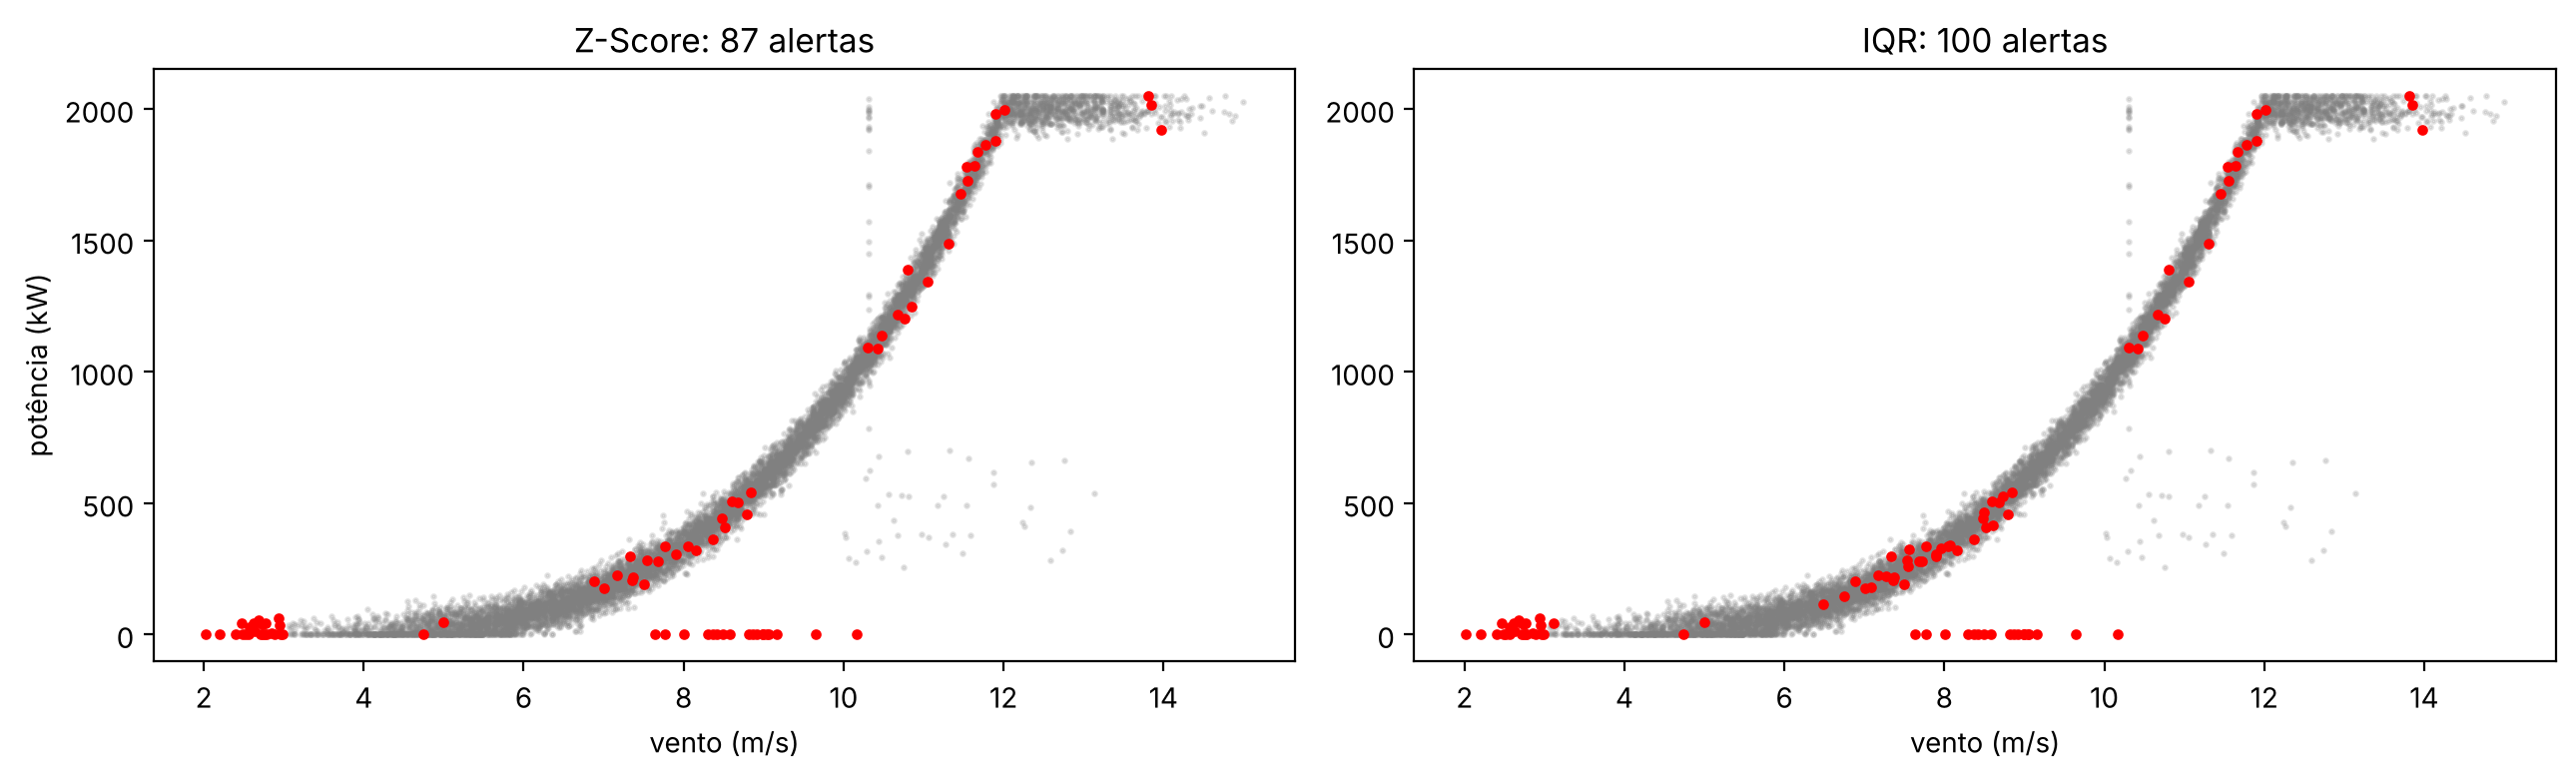

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col, nome in [(ax[0], 'alerta_z', 'Z-Score'), (ax[1], 'alerta_iqr', 'IQR')]:
    a.scatter(d.vento_ms, d.potencia_kw, s=2, alpha=.2, c='gray')
    s = d[d[col]]
    a.scatter(s.vento_ms, s.potencia_kw, s=8, c='red')
    a.set_title(f'{nome}: {len(s)} alertas'); a.set_xlabel('vento (m/s)')
ax[0].set_ylabel('potência (kW)')
plt.tight_layout()

**Comparação.** Os dois quase coincidem (86 em comum) e olham uma coluna de cada vez, então só pegam valores extremos *sozinhos*: os picos de vibração, alguns picos de temperatura e rotor com rpm perto de zero. Esse último é em boa parte **falso positivo**: com vento abaixo de 3 m/s a turbina fica parada mesmo, é o comportamento normal da curva. O IQR dá um pouco mais de alertas porque a vibração tem distribuição estreita e a "cerca" de 1,5·IQR fica apertada.

**O que eles não enxergam:**
- *Potência baixa com vento forte*: 400 kW é um valor normal para vento de 7 m/s. O problema está na **relação** vento × potência, e cada coluna isolada parece normal.
- *Temperatura alta de madrugada*: 60 °C é normal ao meio-dia com carga cheia; com a turbina quase parada à noite, não é. É anomalia **contextual**.
- *Sensor congelado*: 10,31 m/s é um vento perfeitamente comum. O problema é ele se repetir 24 vezes seguidas, e isso só aparece olhando o **tempo**.
- *Derivas lentas* (T03 esquentando por horas, T09 vibrando mais por horas): cada leitura é só um pouco alta; o que chama atenção é a sequência.

## Etapa 3 · Métodos de ML
Primeiro com as colunas originais (normalizadas), depois com atributos derivados.

In [ ]:
X = StandardScaler().fit_transform(d[NUM])

def rodar_metodos(X):
    sc = {}
    iso = IsolationForest(n_estimators=300, random_state=42).fit(X)
    sc['iso'] = -iso.score_samples(X)

    lof = LocalOutlierFactor(n_neighbors=50)
    lof.fit_predict(X)
    sc['lof'] = -lof.negative_outlier_factor_

    dist, _ = NearestNeighbors(n_neighbors=11).fit(X).kneighbors(X)
    sc['knn'] = dist[:, 1:].mean(axis=1)

    amostra = np.random.default_rng(0).choice(len(X), 2000, replace=False)
    oc = OneClassSVM(kernel='rbf', gamma='scale', nu=0.03).fit(X[amostra])
    sc['ocsvm'] = -oc.decision_function(X)
    return pd.DataFrame(sc, index=d.index)

cru = rodar_metodos(X)

def top(s, n=300):
    return set(d.id[s.nlargest(n).index])

for a in cru:
    print(a, [len(top(cru[a]) & top(cru[b])) for b in cru])

iso [300, 137, 122, 171]
lof [137, 300, 245, 216]
knn [122, 245, 300, 216]
ocsvm [171, 216, 216, 300]


A tabela acima mostra quantos dos 300 alertas mais fortes de cada método coincidem com os dos outros. Com as colunas cruas os métodos discordam bastante (Isolation Forest e k-NN dividem só ~120 dos 300): cada um acha "estranho" uma coisa diferente (pontos com vento muito alto, madrugadas frias…), porque nada nas colunas originais diz o que é *esperado* para uma turbina.

### Atributos derivados
A ideia é transformar "conhecimento de turbina" em colunas:

| atributo | como calcula | o que pega |
|---|---|---|
| `res_pot` | potência − mediana da potência para aquela faixa de vento (0,5 m/s) | turbina gerando menos do que devia, parada com vento |
| `res_vib` | vibração − reta vibração × rpm (ajustada com rotor girando) | vibração alta para aquela rotação |
| `res_temp` | temp. caixa − regressão (potência, temp. ambiente) | caixa quente demais para a carga e o clima |
| `vib_1h`, `temp_1h` | mediana móvel de 1h (6 leituras) dos resíduos, por turbina | derivas lentas (coletivas) |
| `congelado` | tamanho da sequência de leituras de vento **idênticas** (só conta a partir de 3) | anemômetro travado |

In [ ]:
# potência esperada pela curva (mediana por faixa de 0,5 m/s)
d['faixa'] = (d.vento_ms * 2).round() / 2
d['pot_esperada'] = d.groupby('faixa').potencia_kw.transform('median')
d['res_pot'] = d.potencia_kw - d.pot_esperada

# vibração esperada para a rotação (só com o rotor girando)
girando = d.rotor_rpm > 5
a, b = np.polyfit(d.rotor_rpm[girando], d.vibracao_mm_s[girando], 1)
d['res_vib'] = d.vibracao_mm_s - (a * d.rotor_rpm + b)

# temperatura esperada da caixa: depende da carga e do dia
m = np.c_[d.potencia_kw, d.temp_ambiente_c, np.ones(len(d))]
coef = np.linalg.lstsq(m, d.temp_caixa_engrenagem_c, rcond=None)[0]
d['res_temp'] = d.temp_caixa_engrenagem_c - m @ coef
print(f'vibração ≈ {a:.3f}·rpm + {b:.2f}')
print(f'temp. caixa ≈ {coef[0]:.4f}·potência + {coef[1]:.2f}·temp_amb + {coef[2]:.1f}')

# janelas de 1h por turbina
mediana_1h = lambda s: s.rolling(6, center=True, min_periods=3).median()
d['vib_1h'] = d.groupby('turbina').res_vib.transform(mediana_1h)
d['temp_1h'] = d.groupby('turbina').res_temp.transform(mediana_1h)

# leituras de vento idênticas em sequência
bloco = (d.vento_ms != d.groupby('turbina').vento_ms.shift()).cumsum()
d['repeticoes'] = d.groupby(bloco).vento_ms.transform('size')
d['congelado'] = np.where(d.repeticoes >= 3, d.repeticoes, 1)

novas = ['res_pot', 'res_vib', 'res_temp', 'vib_1h', 'temp_1h', 'congelado']
d[novas].describe().round(2)

vibração ≈ 0.179·rpm + 1.24
temp. caixa ≈ 0.0117·potência + 1.04·temp_amb + 14.4


,res_pot,res_vib,res_temp,vib_1h,temp_1h,congelado
count,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00
mean,-3.03,0.00,-0.00,-0.02,-0.17,1.05
std,98.24,0.53,2.40,0.18,0.81,1.12
min,-1715.52,-0.99,-5.53,-0.46,-2.38,1.00
25%,-35.17,-0.20,-1.05,-0.11,-0.60,1.00
50%,0.00,-0.03,-0.21,-0.03,-0.22,1.00
75%,37.72,0.14,0.63,0.05,0.17,1.00
max,878.43,9.14,30.51,2.62,12.46,24.00


Por que `congelado` só conta a partir de 3? Os valores têm duas casas decimais, então duas leituras iguais seguidas acontecem por acaso (umas 80 vezes no conjunto). Três ou mais já é raro, e 24 seguidas é impossível com vento de verdade.

In [ ]:
print(d[d.repeticoes >= 3].groupby(['turbina', bloco]).agg(
    inicio=('timestamp', 'first'), fim=('timestamp', 'last'),
    leituras=('id', 'size'), vento=('vento_ms', 'first')).reset_index(level=1, drop=True))

                     inicio                 fim  leituras  vento
turbina                                                         
T07     2026-08-06 11:20:00 2026-08-06 15:10:00        24  10.31


In [ ]:
X2 = StandardScaler().fit_transform(d[novas])
der = rodar_metodos(X2)

for a in der:
    print(a, [len(top(der[a]) & top(der[b])) for b in der])

iso [300, 218, 265, 258]
lof [218, 300, 244, 226]
knn [265, 244, 300, 267]
ocsvm [258, 226, 267, 300]


Com os atributos derivados, k-NN, Isolation Forest e One-Class SVM passam a concordar muito mais (o LOF continua diferente: ele mede densidade *local*, e as anomalias coletivas formam grupinhos densos entre si, então parecem "normais" para ele).

### Combinação
Junto Isolation Forest e k-NN pela média do ranking percentual, como sugerido no enunciado. Os dois erram de jeitos diferentes: o IF às vezes deixa passar um ponto isolado, o k-NN às vezes sobe pontos que estão só um pouco longe de tudo.

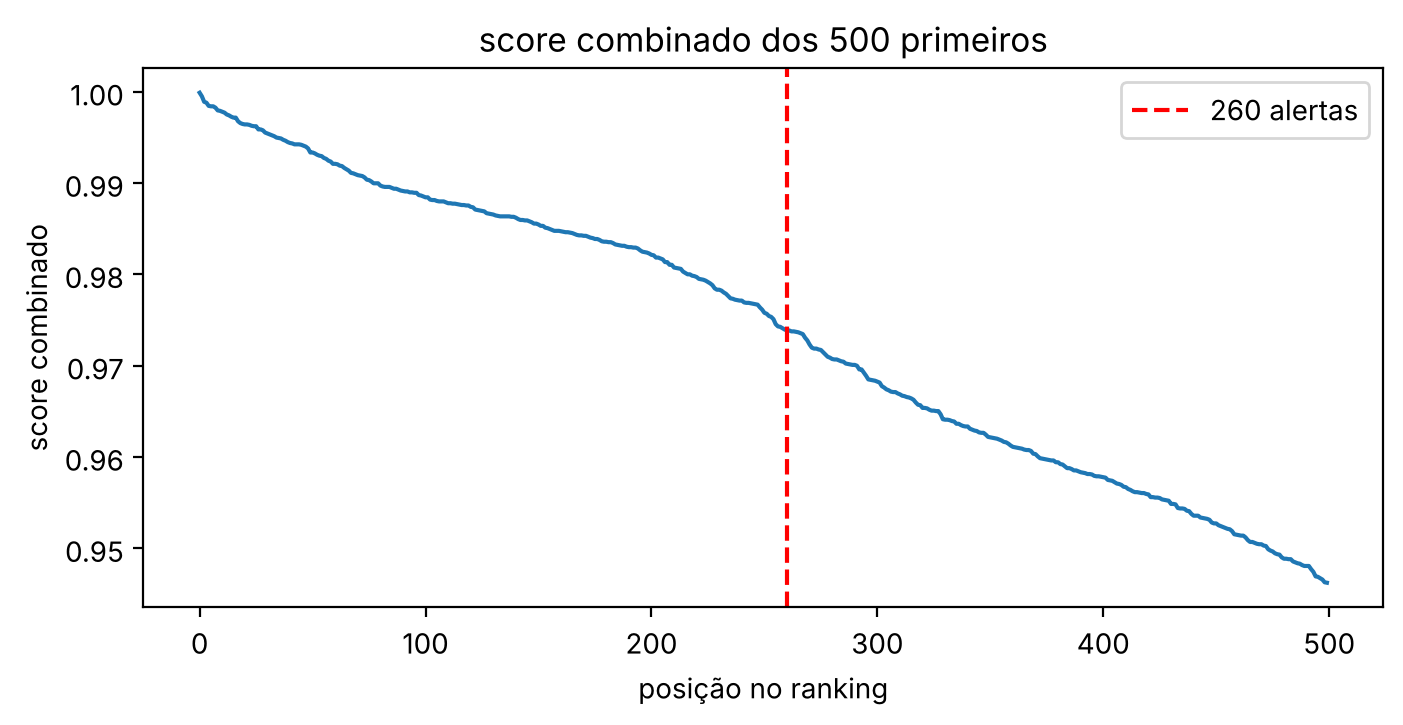

In [ ]:
d['score_iso'] = der.iso
d['score_knn'] = der.knn
d['score_comb'] = d[['score_iso', 'score_knn']].rank(pct=True).mean(axis=1)


ordenado = d.score_comb.sort_values(ascending=False).reset_index(drop=True)
plt.figure(figsize=(8, 3.5))
plt.plot(ordenado.values[:500])
plt.axvline(260, c='red', ls='--', label='260 alertas')
plt.xlabel('posição no ranking'); plt.ylabel('score combinado'); plt.legend()
plt.title('score combinado dos 500 primeiros');

## Etapa 4 · Gerar a submissão

O F1 pune tanto o que falta quanto o que sobra. Pelas contagens da exploração, existem em torno de 240–250 leituras realmente problemáticas; mandar 300 é pagar ~50 falsos positivos garantidos. Fico com 260: cobre os grupos encontrados e ainda deixa uma folga para anomalias que eu não identifiquei manualmente.

In [ ]:
EQUIPE = 'equipe_X'
n_alertas = 260

escolhidos = d.nlargest(n_alertas, 'score_comb')[['id']]
escolhidos.to_csv(f'alertas_{EQUIPE}.csv', index=False)
print(len(escolhidos), 'alertas salvos')

260 alertas salvos


### Conferência: o que entrou na lista?


In [ ]:
alertas = d.loc[d.nlargest(n_alertas, 'score_comb').index].copy()

def motivo(r):
    if r.congelado >= 6:                         return 'anemômetro congelado'
    if r.potencia_kw == 0 and r.vento_ms > 6:    return 'parada com vento'
    if r.res_vib > 2:                            return 'pico de vibração'
    if r.vib_1h > 0.7:                           return 'vibração alta contínua'
    if r.res_pot < -300:                         return 'potência abaixo da curva'
    if r.res_temp > 8 or r.temp_1h > 2.5:        return 'caixa superaquecida'
    return 'outros'

alertas['motivo'] = alertas.apply(motivo, axis=1)
print(alertas.motivo.value_counts())
alertas.groupby(['motivo', 'turbina']).size().unstack(fill_value=0)

motivo
caixa superaquecida         88
potência abaixo da curva    40
pico de vibração            37
vibração alta contínua      29
anemômetro congelado        24
outros                      24
parada com vento            18
Name: count, dtype: int64


turbina,T01,T02,T03,T04,T05,T06,T07,T08,T09,T10
motivo,,,,,,,,,,
anemômetro congelado,0,0,0,0,0,0,24,0,0,0
caixa superaquecida,7,3,34,9,2,5,7,8,5,8
outros,2,3,4,0,2,3,1,2,5,2
parada com vento,0,0,0,0,18,0,0,0,0,0
pico de vibração,4,5,2,6,1,3,7,2,4,3
potência abaixo da curva,4,5,5,9,3,1,3,2,4,4
vibração alta contínua,0,0,0,0,1,0,0,0,28,0


## Etapa 5 · Para a apresentação

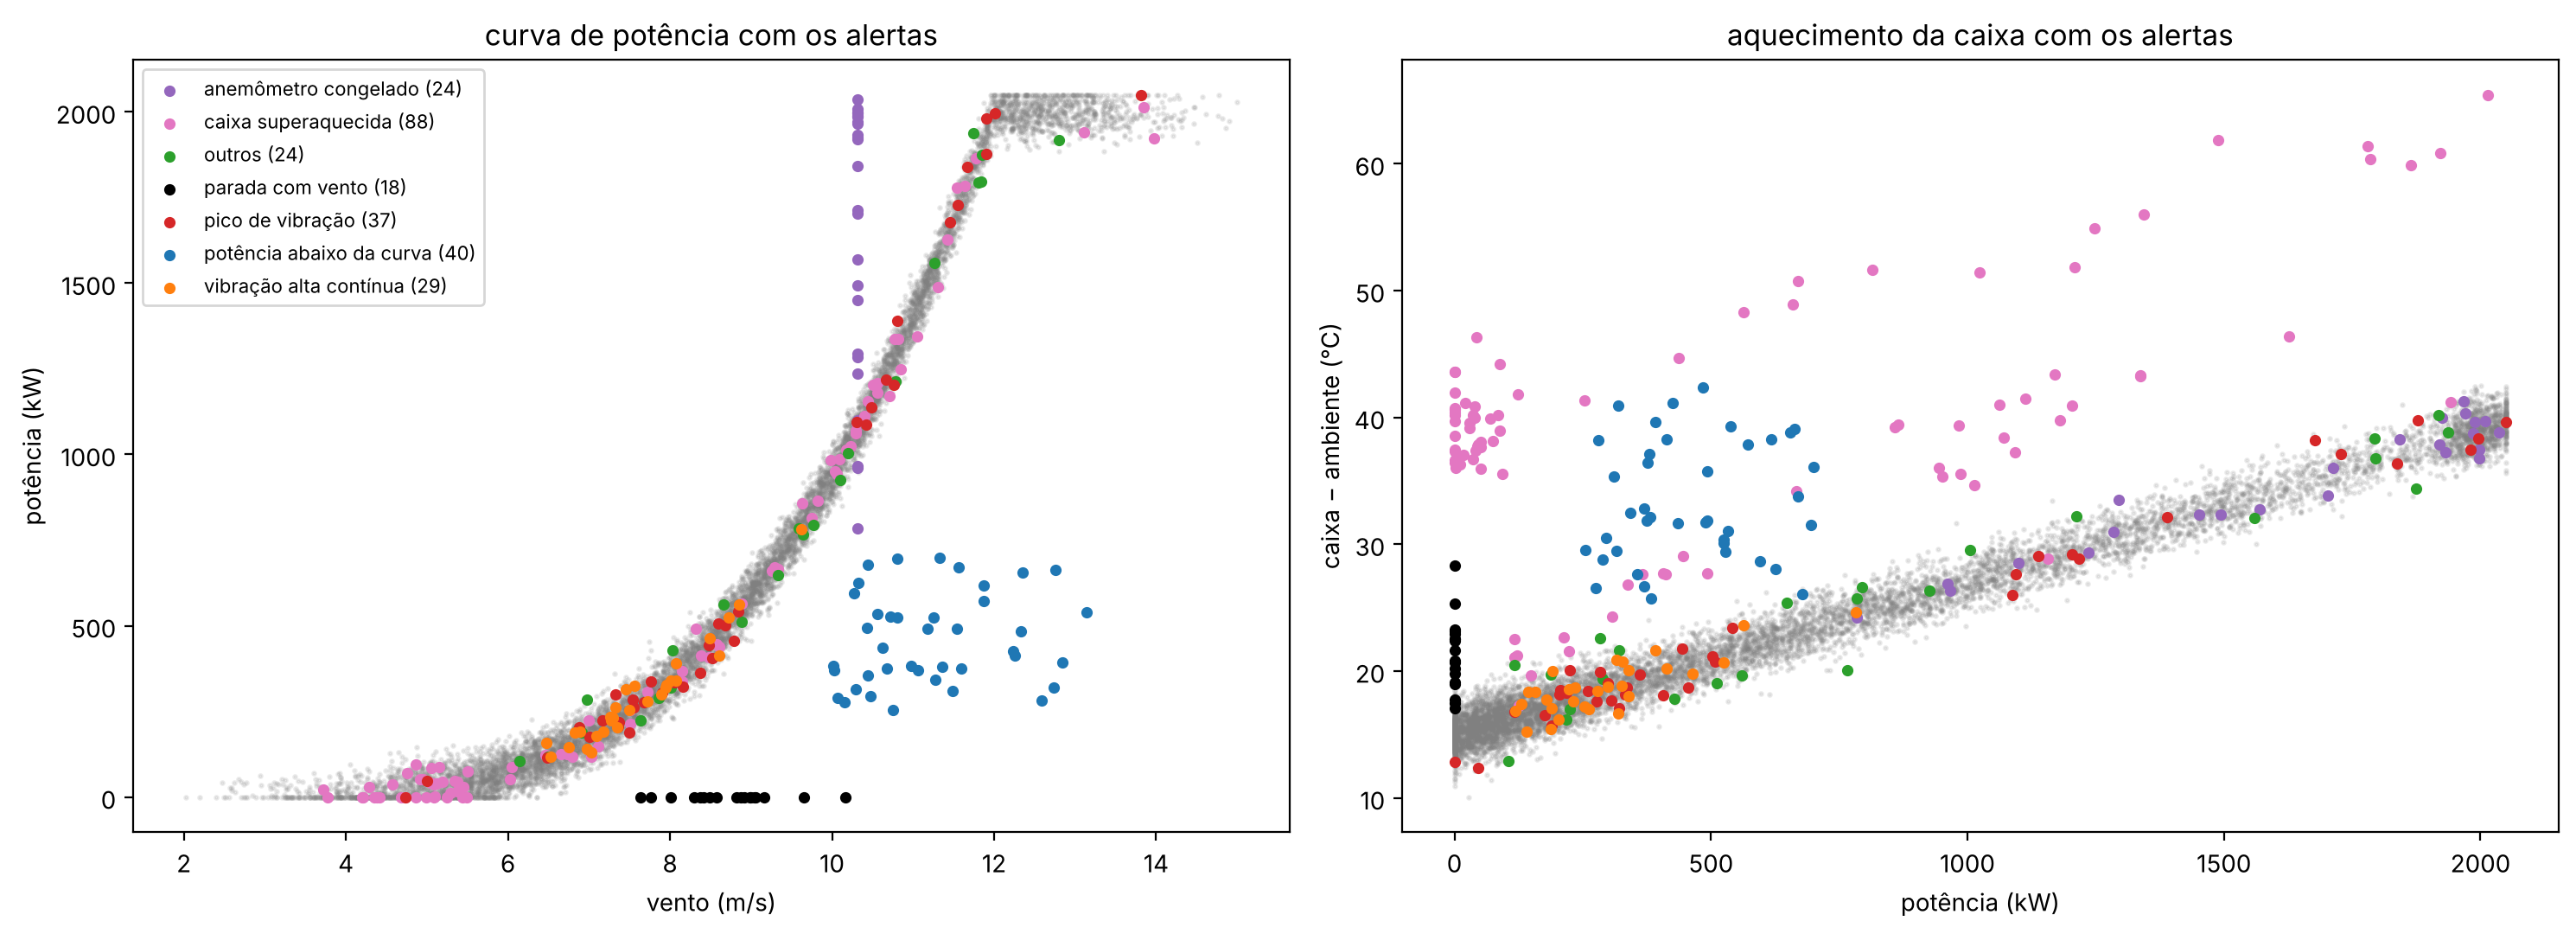

In [ ]:
cores = {'anemômetro congelado': 'tab:purple', 'parada com vento': 'black', 'pico de vibração': 'tab:red',
         'vibração alta contínua': 'tab:orange', 'caixa superaquecida': 'tab:pink',
         'potência abaixo da curva': 'tab:blue', 'outros': 'tab:green'}

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].scatter(d.vento_ms, d.potencia_kw, s=2, alpha=.15, c='gray')
ax[1].scatter(d.potencia_kw, d.temp_caixa_engrenagem_c - d.temp_ambiente_c, s=2, alpha=.15, c='gray')
for nome, g in alertas.groupby('motivo'):
    ax[0].scatter(g.vento_ms, g.potencia_kw, s=14, c=cores[nome], label=f'{nome} ({len(g)})')
    ax[1].scatter(g.potencia_kw, g.temp_caixa_engrenagem_c - g.temp_ambiente_c, s=14, c=cores[nome])
ax[0].set_xlabel('vento (m/s)'); ax[0].set_ylabel('potência (kW)'); ax[0].legend(fontsize=8)
ax[0].set_title('curva de potência com os alertas')
ax[1].set_xlabel('potência (kW)'); ax[1].set_ylabel('caixa − ambiente (°C)')
ax[1].set_title('aquecimento da caixa com os alertas')
plt.tight_layout()

### Alertas explicados

In [ ]:
cols = ['id', 'turbina', 'timestamp', 'vento_ms', 'potencia_kw', 'pot_esperada', 'rotor_rpm',
        'temp_caixa_engrenagem_c', 'temp_ambiente_c', 'res_temp', 'vibracao_mm_s', 'res_vib']

pico = alertas[alertas.motivo == 'pico de vibração'].nlargest(1, 'res_vib')
baixa = alertas[alertas.motivo == 'potência abaixo da curva'].nsmallest(1, 'res_pot')
deriva = d[(d.turbina == 'T03') & (d.timestamp.between('2026-08-08 06:00', '2026-08-08 13:00'))]

print('1) pico de vibração'); display(pico[cols])
print('2) potência abaixo da curva'); display(baixa[cols])
print('3) deriva térmica T03 (de hora em hora)'); display(deriva[cols].iloc[::6])

1) pico de vibração


,id,turbina,timestamp,vento_ms,potencia_kw,pot_esperada,rotor_rpm,temp_caixa_engrenagem_c,temp_ambiente_c,res_temp,vibracao_mm_s,res_vib
1643,1644,T02,2026-08-07 09:50:00,8.52,406.6,457.38,14.58,45.45,27.35,-2.15,12.99,9.14


2) potência abaixo da curva


,id,turbina,timestamp,vento_ms,potencia_kw,pot_esperada,rotor_rpm,temp_caixa_engrenagem_c,temp_ambiente_c,res_temp,vibracao_mm_s,res_vib
9862,9863,T10,2026-08-08 11:40:00,12.59,280.98,1996.51,18.04,68.54,30.35,19.3,4.37,-0.1


3) deriva térmica T03 (de hora em hora)


,id,turbina,timestamp,vento_ms,potencia_kw,pot_esperada,rotor_rpm,temp_caixa_engrenagem_c,temp_ambiente_c,res_temp,vibracao_mm_s,res_vib
2772,2773,T03,2026-08-08 06:00:00,7.97,311.79,343.05,13.49,47.42,25.46,2.90,3.48,-0.18
2778,2779,T03,2026-08-08 07:00:00,6.91,187.67,176.96,13.62,44.30,24.58,2.15,3.22,-0.46
2784,2785,T03,2026-08-08 08:00:00,7.00,223.29,176.96,13.03,47.70,26.14,3.51,3.08,-0.49
2790,2791,T03,2026-08-08 09:00:00,8.15,337.57,343.05,13.70,53.17,26.39,7.38,4.20,0.51
2796,2797,T03,2026-08-08 10:00:00,10.09,986.14,939.02,16.32,63.82,28.26,8.48,4.29,0.13
2802,2803,T03,2026-08-08 11:00:00,9.63,858.35,755.23,15.98,67.57,28.34,13.64,4.27,0.17
2808,2809,T03,2026-08-08 12:00:00,10.40,1113.56,1158.15,16.55,71.42,29.94,12.83,4.00,-0.20
2814,2815,T03,2026-08-08 13:00:00,11.33,1619.27,1678.12,17.24,64.61,30.27,-0.26,4.52,0.19


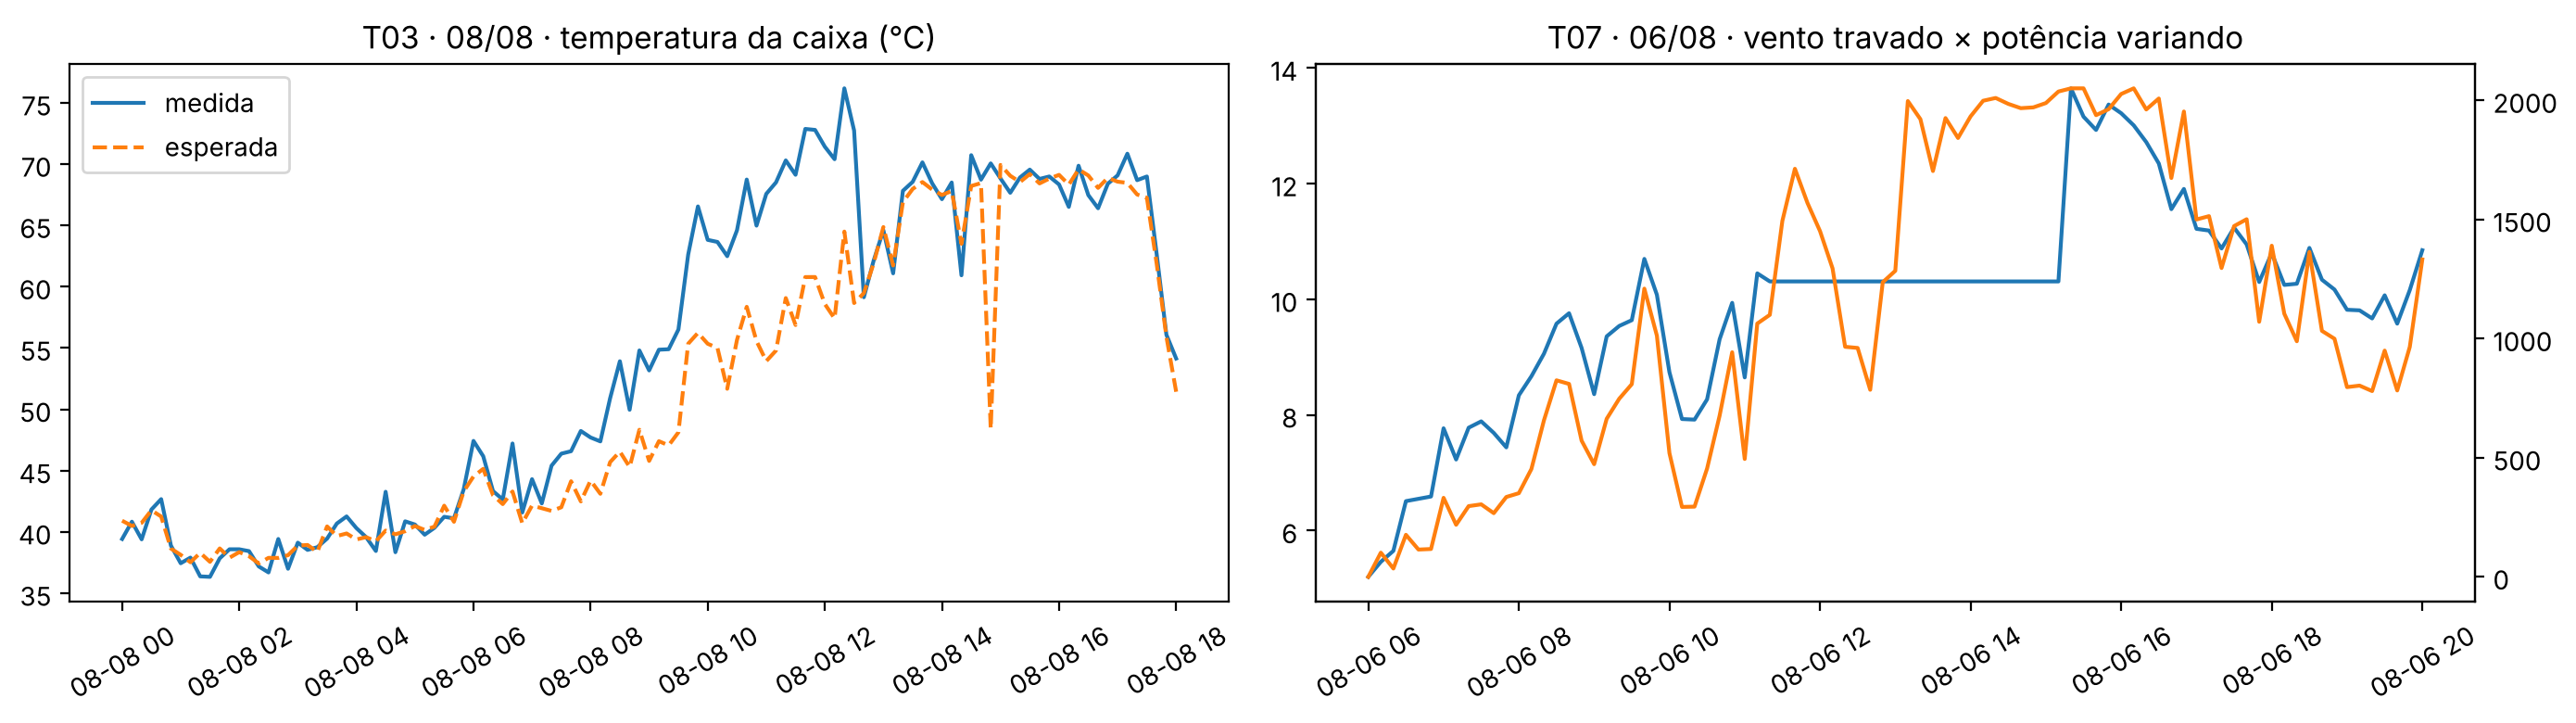

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
g = d[(d.turbina == 'T03') & (d.timestamp.between('2026-08-08 00:00', '2026-08-08 18:00'))]
ax[0].plot(g.timestamp, g.temp_caixa_engrenagem_c, label='medida')
ax[0].plot(g.timestamp, g.temp_caixa_engrenagem_c - g.res_temp, label='esperada', ls='--')
ax[0].set_title('T03 · 08/08 · temperatura da caixa (°C)'); ax[0].legend()

g = d[(d.turbina == 'T07') & (d.timestamp.between('2026-08-06 06:00', '2026-08-06 20:00'))]
ax[1].plot(g.timestamp, g.vento_ms, label='vento (m/s)')
a2 = ax[1].twinx(); a2.plot(g.timestamp, g.potencia_kw, c='tab:orange', label='potência')
ax[1].set_title('T07 · 06/08 · vento travado × potência variando')
for a in ax: a.tick_params(axis='x', rotation=30)
plt.tight_layout()

1) Pico de vibração - anomalia pontual.
Para o técnico: *"a turbina estava girando em rotação normal e, numa única leitura, a vibração do trem de força foi para mais de 3× o normal, voltando logo depois. Pode ser um choque mecânico (folga em rolamento, dente de engrenagem, rajada atingindo a pá) ou um defeito no acelerômetro. Vale inspecionar o rolamento principal e o cabo do sensor; se repetir, é desgaste."*
É pontual porque o valor é absurdo sozinho, até o Z-Score pega.

2) Potência abaixo da curva - anomalia contextual.
Para o técnico: *"vento acima de 10 m/s, rotor girando na rotação de carga alta e caixa de engrenagem quente como se estivesse gerando perto do nominal, mas o medidor marca um terço do que a curva prevê. Ou a energia está se perdendo entre o gerador e a medição (conversor, cabo, disjuntor), ou o próprio transdutor de potência está lendo errado. Conferir log do conversor e comparar com o medidor da subestação."*
(Repare no gráfico da direita: os pontos azuis estão bem acima da reta de aquecimento, porque a caixa "sabe" a carga real.)
É contextual: 400 kW é um valor comum no parque; só é errado *para aquele vento*.

3) Deriva térmica da T03 em 08/08 - anomalia coletiva.
Para o técnico: *"a caixa de engrenagem da T03 foi esquentando cada vez mais acima do esperado entre ~06h30 e 12h30, até ficar 14 °C acima do normal para a carga, e então caiu de repente. Típico de problema de lubrificação ou de arrefecimento (bomba de óleo, radiador sujo, ventilador). A queda brusca sugere que alguém interveio ou que o sistema de proteção atuou. Verificar nível e filtro de óleo e o trocador de calor."*
É **coletiva**: as primeiras leituras estão só 3–4 °C acima, dentro do ruído. O padrão só aparece olhando a sequência.


